# Панель прогресса ROADMAP-ML

Мой пульт: **Run All** (запустить всё) — и видно, где я сейчас и что изменилось с прошлого раза. Терминал не нужен.

**Где что лежит**

| Что | Где | Кто меняет |
|---|---|---|
| Эталоны методов | `src/<этап>/<подраздел>/<метод>.py` или `.../<метод>/<метод>.py` | я: код + шапка `# status:` |
| Таблица тем | `roadmap_tracker.csv` | скрипт пересобирает из `src/`; руками — только `repeated` |
| История | `progress_history.csv` | скрипт дописывает строку, когда проценты изменились |
| Картинка | `assets/progress.png` | скрипт |
| Отчёт | `README.md` | скрипт (руками не править) |
| Лог | `logs/progress.log` | скрипт, перезаписывается при каждом запуске |

**Что значат цифры**

- `status` в шапке файла: `todo` — не начинал, `in_progress` — в работе, `ready` — закрыл.
- `learned` — из статуса: todo → **0**, in_progress → **0.5**, ready → **1**.
- `repeated` — сколько раз повторил тему; 4 повторения = 100%, по нему красится кубик.
- `readme`, `experiment`, `test_create` — 1, если есть непустой README метода, ноутбук в `experiments/<slug>/`, тест `test_<slug>.py`.
- `test_run` — **1** = тест сломан (значок `!`). Проставляется сам при запуске с `pytest=True`.
- Значок `?` — в шапке нет строки `status` или статус не из словаря.

In [65]:
# Настройка: находим корень репозитория и подключаем скрипт
import importlib, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent   # ноутбук лежит в notebooks/
sys.path.insert(0, str(ROOT / "scripts"))
import update_progress as up
importlib.reload(up)                                    # подхватить правки скрипта без перезапуска ядра (kernel)
pd.set_option("display.max_rows", 300, "display.max_colwidth", 80)
RUN_PYTEST = True                                       # прогнать тесты и проставить test_run автоматически
print("Корень:", ROOT)

Корень: /Users/nakhvamdis-ka/research/ROADMAP-ML


## 1. Пересборка

Обходит `src/`, пересобирает таблицу (ручное поле `repeated` сохраняется), пишет историю и лог, рисует картинку и README. Ниже — что изменилось по сравнению с таблицей до запуска.

In [66]:
csv = ROOT / "roadmap_tracker.csv"
before = pd.read_csv(csv, encoding="utf-8-sig", dtype=str, keep_default_na=False) if csv.exists() else pd.DataFrame(columns=up.COLUMNS)
df, log = up.main(ROOT, verbose=False, pytest=RUN_PYTEST)
after = pd.read_csv(csv, encoding="utf-8-sig", dtype=str, keep_default_na=False)

# что поменялось: сравниваем по path
b = before.set_index("path") if "path" in before.columns else pd.DataFrame()
a = after.set_index("path")
added, removed = sorted(set(a.index) - set(b.index)), sorted(set(b.index) - set(a.index))
changes = [{"path": p, "поле": c, "было": b.at[p, c], "стало": a.at[p, c]}
           for p in a.index.intersection(b.index) for c in a.columns
           if c in b.columns and b.at[p, c] != a.at[p, c]]
print(f"Тем: {len(after)} (было {len(before)}), новых: {len(added)}, пропало: {len(removed)}, изменённых ячеек: {len(changes)}")
for p in added:
    print("  + ", p)
for p in removed:
    print("  − ", p)
display(pd.DataFrame(changes) if changes else Markdown("_Ячейки не менялись._"))

Тем: 244 (было 244), новых: 0, пропало: 0, изменённых ячеек: 0


_Ячейки не менялись._

## 2. Картинка прогресса

Кубик = тема, столбец = подраздел, рамка = этап. Цвет — повторения; штриховка — сколько из четырёх задач (изучить, README, эксперимент, тест) ещё не сделано; **оранжевая рамка** — in_progress; `!` — тест сломан; `?` — нет статуса.

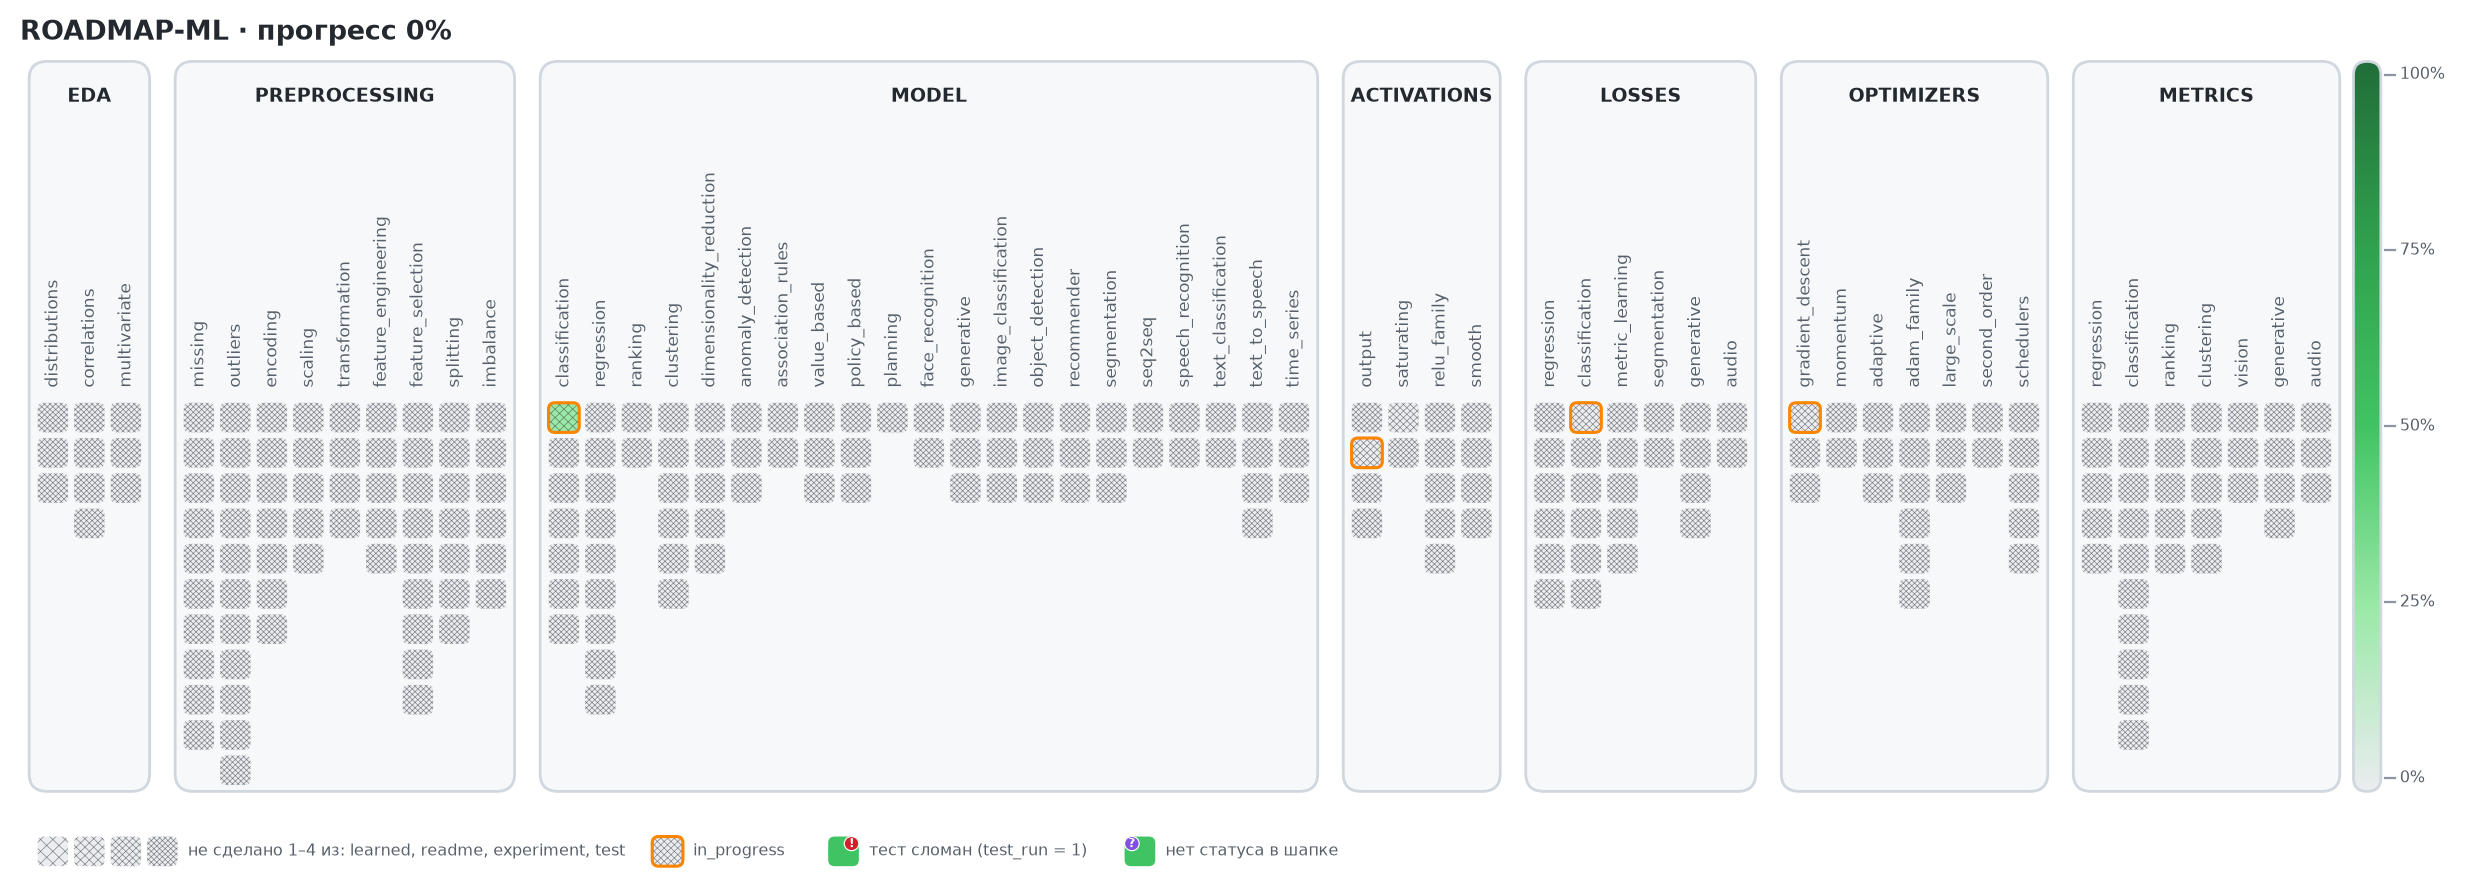

In [67]:
display(Image(filename=str(ROOT / "assets" / "progress.png")))

## 3. Проценты по этапам и история

**Готовность** — среднее `learned`. **Повторения** — `repeated` / 4, как цвет кубиков. История пишется только когда проценты меняются.

In [68]:
display(up.stage_summary(df))
hist_path = ROOT / "progress_history.csv"
if hist_path.exists():
    hist = pd.read_csv(hist_path, encoding="utf-8-sig", parse_dates=["datetime"])
    display(hist.tail(10))
    if len(hist) > 1:
        hist.set_index("datetime")[up.HISTORY_COLS[1:]].plot(figsize=(9, 3.5), marker="o", ylabel="готовность, %", grid=True)

,этап,тем,ready,in_progress,todo,"готовность, %","повторения, %"
0,eda,10,0,0,10,0.0,0.0
1,preprocessing,64,0,0,64,0.0,0.0
2,model,71,0,1,70,0.7,0.4
3,activations,15,0,1,14,3.3,0.0
4,losses,25,0,1,24,2.0,0.0
5,optimizers,24,0,1,23,2.1,0.0
6,metrics,35,0,0,35,0.0,0.0
7,всего,244,0,4,240,0.8,0.1


,datetime,всего,eda,preprocessing,model,activations,losses,optimizers,metrics
0,2026-10-14 21:21:18,0.8,0.0,0.0,0.7,3.3,2.0,2.1,0.0


## 4. Где проблемы

In [69]:
d = up.numeric(df)
cols = ["slug", "stage", "subsection", "path"]

display(Markdown(f"**`!` Сломан тест (test_run = 1) — {int((d.test_run == 1).sum())}**"))
display(d.loc[d.test_run == 1, cols])
bad = ~d.status.isin(up.LEARNED)
display(Markdown(f"**`?` Нет или неверный статус — {int(bad.sum())}**"))
display(d.loc[bad, cols + ["status"]])

**`!` Сломан тест (test_run = 1) — 0**

,slug,stage,subsection,path


**`?` Нет или неверный статус — 0**

,slug,stage,subsection,path,status


In [70]:
# Полный лог последнего запуска (logs/progress.log)
print((ROOT / "logs" / "progress.log").read_text(encoding="utf-8"))

# update_progress 2026-10-14 21:33:36
INFO  tests/activations/test_sigmoid.py: pytest — no tests ran in 0.00s
INFO  tests/losses/test_log_loss.py: pytest — no tests ran in 0.00s
INFO  tests/model/test_logistic_regression.py: pytest — no tests ran in 0.02s
INFO  tests/optimizers/test_batch_gd.py: pytest — no tests ran in 0.01s
INFO  progress_history.csv: проценты не изменились — строка не дописана



## 5. Изучено / в работе / в планах

In [71]:
cols = ["slug", "stage", "subsection", "path", "description"]
for title, status in [("Изучено (ready)", "ready"), ("В работе (in_progress)", "in_progress")]:
    g = d[d.learned == 1] if status == "ready" else d[d.status == status]
    display(Markdown(f"**{title} — {len(g)}**"))
    display(g[cols] if len(g) else Markdown("_пусто_"))

plans = d[d.status == "todo"]
# display(Markdown(f"**В планах (todo) — {len(plans)}**, по этапам:"))
# display(plans.groupby("stage", sort=False).size().rename("тем").to_frame())

**Изучено (ready) — 0**

_пусто_

**В работе (in_progress) — 4**

,slug,stage,subsection,path,description
74,logistic_regression,model,classification,src/model/classification/logistic_regression/logistic_regression.py,
146,sigmoid,activations,output,src/activations/output/sigmoid.py,
166,log_loss,losses,classification,src/losses/classification/log_loss.py,
185,batch_gd,optimizers,gradient_descent,src/optimizers/gradient_descent/batch_gd.py,


In [72]:
# Список планов целиком, по этапам и подразделам
for stage in up.ORDER:
    g = plans[plans.stage == stage]
    if len(g):
        print(f"\n{stage.upper()} — {len(g)}")
        for sub, sg in g.groupby("subsection", sort=False):
            print(f"  {sub}: " + ", ".join(sg.slug))


EDA — 10
  distributions: histogram, kde, boxplot
  correlations: pearson, spearman, cramers_v, mutual_information
  multivariate: pairplot, heatmap, pca_projection

PREPROCESSING — 64
  missing: missing_report, missing_pattern, drop, mean_median_mode, constant, interpolation, knn_imputer, iterative_imputer, missing_indicator, ffill_bfill
  outliers: iqr, z_score, modified_z_score, isolation_forest, lof, dbscan, remove, clip, log_transform, impute, flag
  encoding: one_hot, label, ordinal, target, frequency, binary, hashing
  scaling: standard, minmax, robust, maxabs, normalizer
  transformation: log, box_cox, yeo_johnson, quantile
  feature_engineering: polynomial, interactions, binning, datetime_features, aggregations
  feature_selection: variance_threshold, correlation, chi2, mutual_information, rfe, forward_selection, backward_elimination, lasso, tree_importance
  splitting: holdout, stratified, kfold, stratified_kfold, group_kfold, time_series_split, leave_one_out
  imbalance: ra

## 6. Вся таблица

Руками правлю только `repeated` в `roadmap_tracker.csv`; статус — в шапке файла. Потом перезапускаю ноутбук.

In [73]:
df

,stage,subsection,slug,path,description,status,learned,repeated,readme,experiment,test_create,test_run
0,eda,distributions,histogram,src/eda/distributions/histogram.py,,todo,0,0,0,0,0,0
1,eda,distributions,kde,src/eda/distributions/kde.py,,todo,0,0,0,0,0,0
2,eda,distributions,boxplot,src/eda/distributions/boxplot.py,,todo,0,0,0,0,0,0
3,eda,correlations,pearson,src/eda/correlations/pearson.py,,todo,0,0,0,0,0,0
4,eda,correlations,spearman,src/eda/correlations/spearman.py,,todo,0,0,0,0,0,0
5,eda,correlations,cramers_v,src/eda/correlations/cramers_v.py,,todo,0,0,0,0,0,0
6,eda,correlations,mutual_information,src/eda/correlations/mutual_information.py,,todo,0,0,0,0,0,0
7,eda,multivariate,pairplot,src/eda/multivariate/pairplot.py,,todo,0,0,0,0,0,0
8,eda,multivariate,heatmap,src/eda/multivariate/heatmap.py,,todo,0,0,0,0,0,0
9,eda,multivariate,pca_projection,src/eda/multivariate/pca_projection.py,,todo,0,0,0,0,0,0
